# Adventure Works Internet Sales Analysis
Christina Fan | Case Study Report Assignment 2

Run the cells in order. Upload only the supplied InternetSales CSV when prompted. Amounts use the dataset's recorded monetary units; no currency conversion is performed.

### 1. Import libraries and upload the file
Load pandas and Matplotlib, then upload the provided CSV. Latin-1 encoding reads the accented characters in this file.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding='latin1', low_memory=False)
df.head()

### 2. Check the data and create the year
Check the number of rows, missing analysis values, repeated order lines, and the dates covered by each year. The first and last years may be incomplete.

In [2]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year
columns = ['CustomerKey', 'EnglishCountryRegionName', 'Gender', 'YearlyIncome',
           'HouseOwnerFlag', 'EnglishProductName', 'OrderQuantity', 'UnitPrice', 'SalesAmount']
print('Rows and original columns:', len(df), len(df.columns) - 1)
print('Missing values:', df[columns].isna().sum())
print('Repeated order lines:', df.duplicated(['SalesOrderNumber', 'SalesOrderLineNumber']).sum())
coverage = df.groupby('Year')['OrderDate'].agg(['min', 'max', 'nunique'])
display(coverage)

Rows and original columns: 60398 60
Missing values: CustomerKey                 0
EnglishCountryRegionName    0
Gender                      0
YearlyIncome                0
HouseOwnerFlag              0
EnglishProductName          0
OrderQuantity               0
UnitPrice                   0
SalesAmount                 0
dtype: int64
Repeated order lines: 0
            min        max  nunique
Year                               
2010 2010-12-29 2010-12-31        3
2011 2011-01-01 2011-12-31      362
2012 2012-01-01 2012-12-31      366
2013 2013-01-01 2013-12-31      365
2014 2014-01-01 2014-01-28       28


### 3. Create product categories
The file has no category column. Classify Road-, Mountain-, and Touring- model names as Bikes; caps, jerseys, gloves, shorts, socks, and vests as Clothing; and the remaining listed products as Accessories. Display the mapping so it can be checked.

In [3]:
df['Category'] = 'Accessories'
df.loc[df['EnglishProductName'].str.contains('Cap|Jersey|Gloves|Shorts|Socks|Vest'), 'Category'] = 'Clothing'
df.loc[df['EnglishProductName'].str.startswith(('Road-', 'Mountain-', 'Touring-')), 'Category'] = 'Bikes'
display(df[['EnglishProductName', 'Category']].drop_duplicates().sort_values(['Category', 'EnglishProductName']))

                    EnglishProductName     Category
95              All-Purpose Bike Stand  Accessories
158              Bike Wash - Dissolver  Accessories
2                Fender Set - Mountain  Accessories
40                    HL Mountain Tire  Accessories
572                       HL Road Tire  Accessories
122                Hitch Rack - 4-Bike  Accessories
147            Hydration Pack - 70 oz.  Accessories
126                   LL Mountain Tire  Accessories
131                       LL Road Tire  Accessories
128                   ML Mountain Tire  Accessories
111                       ML Road Tire  Accessories
11                Mountain Bottle Cage  Accessories
41                  Mountain Tire Tube  Accessories
31                 Patch Kit/8 Patches  Accessories
17                    Road Bottle Cage  Accessories
80                      Road Tire Tube  Accessories
18             Sport-100 Helmet, Black  Accessories
22              Sport-100 Helmet, Blue  Accessories
6           

### 4. Summarize sales by year and country region
Sum SalesAmount as revenue, excluding the separate tax and freight fields. Retain the partial years but do not interpret them as full-year results.

Year
2010       43421.04
2011     7075525.93
2012     5842485.20
2013    16351550.34
2014       45694.72
Year                          2010        2011        2012        2013      2014
EnglishCountryRegionName                                                        
Australia                 20909.78  2563732.25  2128407.46  4339443.38   8507.72
Canada                     3578.27   571571.80   307604.52  1085632.65   9457.62
France                     3399.99   410845.33   648065.54  1578511.80   3195.06
Germany                       0.00   520500.16   608657.98  1761876.36   3277.83
United Kingdom              699.10   550591.22   712700.96  2124007.29   3713.64
United States             14833.90  2458285.17  1437048.73  5462078.86  17542.85


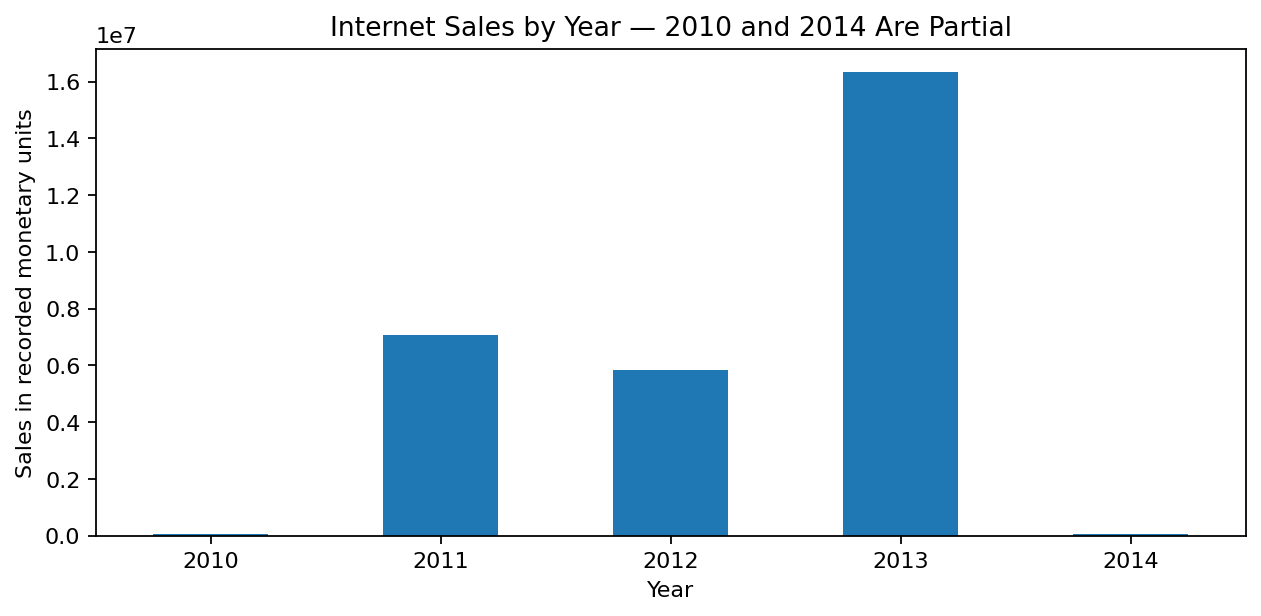

In [4]:
yearly_sales = df.groupby('Year')['SalesAmount'].sum()
country_sales = df.pivot_table(index='EnglishCountryRegionName', columns='Year',
                              values='SalesAmount', aggfunc='sum', fill_value=0)
display(yearly_sales.round(2))
display(country_sales.round(2))
yearly_sales.plot(kind='bar', figsize=(8, 4), rot=0)
plt.title('Internet Sales by Year — 2010 and 2014 Are Partial')
plt.xlabel('Year')
plt.ylabel('Sales in recorded monetary units')
plt.tight_layout()
plt.show()

### 5. Summarize sales by year and product category
Compare category revenue and units sold. Sales means revenue here; units are shown separately to distinguish price from volume.

Category  Accessories        Bikes   Clothing
Year                                         
2010             0.00     43421.04       0.00
2011             0.00   7075525.93       0.00
2012          2147.08   5839695.33     642.79
2013        668241.53  15359502.36  323806.45
2014         30371.35         0.00   15323.37
                 Revenue  Units  RevenueSharePct
Category                                        
Accessories    700759.96  36092             2.39
Bikes        28318144.65  15205            96.46
Clothing       339772.61   9101             1.16


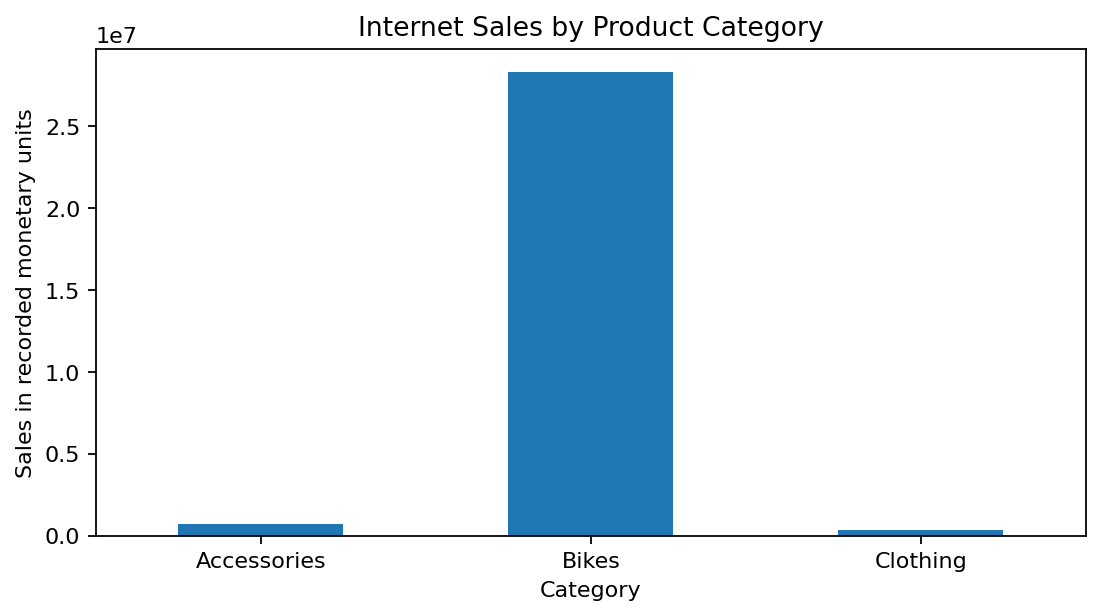

In [5]:
category_year = df.pivot_table(index='Year', columns='Category',
                              values='SalesAmount', aggfunc='sum', fill_value=0)
category_summary = df.groupby('Category').agg(Revenue=('SalesAmount', 'sum'),
                                            Units=('OrderQuantity', 'sum'))
category_summary['RevenueSharePct'] = category_summary['Revenue'] / category_summary['Revenue'].sum() * 100
display(category_year.round(2))
display(category_summary.round(2))
category_summary['Revenue'].plot(kind='bar', figsize=(7, 4), rot=0)
plt.title('Internet Sales by Product Category')
plt.ylabel('Sales in recorded monetary units')
plt.tight_layout()
plt.show()

### 6. Create one record per customer
Customer attributes repeat across purchases. Use one row per CustomerKey for income and gender summaries, so frequent shoppers do not receive extra weight. Check that these attributes are consistent within customers.

In [6]:
attributes = ['EnglishCountryRegionName', 'Gender', 'YearlyIncome', 'HouseOwnerFlag']
print('Maximum distinct values per customer:')
print(df.groupby('CustomerKey')[attributes].nunique().max())
customers = df.drop_duplicates('CustomerKey')
print('Unique purchasing customers:', len(customers))

Maximum distinct values per customer:
EnglishCountryRegionName    1
Gender                      1
YearlyIncome                1
HouseOwnerFlag              1
dtype: int64
Unique purchasing customers: 18484


### 7. Summarize yearly income by country and gender
Calculate customer count, mean, minimum, maximum, and sample standard deviation of income, first by country and then by country and gender.

In [7]:
income_country = customers.groupby('EnglishCountryRegionName')['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])
income_gender = customers.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])
display(income_country.round(2))
display(income_gender.round(2))

                          count      mean    min     max       std
EnglishCountryRegionName                                          
Australia                  3591  64338.62  10000  170000  31830.00
Canada                     1571  57167.41  10000  170000  20251.52
France                     1810  35762.43  10000  110000  27277.40
Germany                    1780  42943.82  10000  130000  35493.58
United Kingdom             1913  52169.37  10000  170000  48431.99
United States              7819  63616.83  10000  170000  25706.48
                                 count      mean    min     max       std
EnglishCountryRegionName Gender                                          
Australia                F        1777  65284.19  10000  160000  31164.36
                         M        1814  63412.35  10000  170000  32450.71
Canada                   F         767  56505.87  10000  170000  19181.55
                         M         804  57798.51  10000  170000  21214.77
France              

### 8. Summarize gender by country
Gender is categorical, so counts and percentages are more meaningful than minimum, maximum, or standard deviation of gender codes. F and M are the labels recorded in this file.

In [8]:
gender_counts = pd.crosstab(customers['EnglishCountryRegionName'], customers['Gender'])
gender_percent = gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100
display(gender_counts)
display(gender_percent.round(2))

Gender                       F     M
EnglishCountryRegionName            
Australia                 1777  1814
Canada                     767   804
France                     893   917
Germany                    874   906
United Kingdom             934   979
United States             3888  3931
Gender                        F      M
EnglishCountryRegionName              
Australia                 49.48  50.52
Canada                    48.82  51.18
France                    49.34  50.66
Germany                   49.10  50.90
United Kingdom            48.82  51.18
United States             49.73  50.27


### 9. Find the average price in the leading category
Identify the category with the highest revenue. Calculate its average realized unit price as revenue divided by units sold. This is sales-weighted, rather than an unweighted average of catalog products.

In [9]:
top_category = category_summary['Revenue'].idxmax()
top_products = df[df['Category'] == top_category]
average_price = top_products['SalesAmount'].sum() / top_products['OrderQuantity'].sum()
print('Highest-revenue category:', top_category)
print('Average realized unit price:', round(average_price, 2))

Highest-revenue category: Bikes
Average realized unit price: 1862.42


### 10. Compare sales by home ownership
Compare totals and normalize by unique purchasing customers and orders. HouseOwnerFlag 1 indicates an owner and 0 a non-owner. These are observed associations among buyers, not causal effects or purchase conversion rates.

In [10]:
home_sales = df.groupby('HouseOwnerFlag').agg(Revenue=('SalesAmount', 'sum'),
                                             Customers=('CustomerKey', 'nunique'),
                                             Orders=('SalesOrderNumber', 'nunique'))
home_sales['RevenuePerCustomer'] = home_sales['Revenue'] / home_sales['Customers']
home_sales['RevenuePerOrder'] = home_sales['Revenue'] / home_sales['Orders']
home_sales['OrdersPerCustomer'] = home_sales['Orders'] / home_sales['Customers']
display(home_sales.round(2))

                    Revenue  Customers  Orders  RevenuePerCustomer  RevenuePerOrder  OrdersPerCustomer
HouseOwnerFlag                                                                                        
0                8973327.42       5982    8601             1500.05          1043.29               1.44
1               20385349.80      12502   19058             1630.57          1069.65               1.52


### 11. Compare complete-year growth
Use 2011–2013 for annual growth comparisons. The 2010 and 2014 extracts are incomplete. Compare 2012 with 2013 by country to identify markets for a growth pilot.

In [11]:
display((yearly_sales.loc[2011:2013].pct_change() * 100).round(2).rename('AnnualGrowthPct'))
country_comparison = country_sales[[2012, 2013]].copy()
country_comparison['GrowthPct'] = (country_comparison[2013] / country_comparison[2012] - 1) * 100
display(country_comparison.round(2))

Year
2011       NaN
2012    -17.43
2013    179.87
Year                            2012        2013  GrowthPct
EnglishCountryRegionName                                   
Australia                 2128407.46  4339443.38     103.88
Canada                     307604.52  1085632.65     252.93
France                     648065.54  1578511.80     143.57
Germany                    608657.98  1761876.36     189.47
United Kingdom             712700.96  2124007.29     198.02
United States             1437048.73  5462078.86     280.09


### 12. Interpretation and recommendation
The report uses the outputs above to recommend protecting bike sales, testing accessory and clothing cross-selling, and piloting market-specific campaigns. Partial-year coverage, inferred categories, and unadjusted customer comparisons limit interpretation. No numerical forecast or causal sales uplift is claimed.